# LAB - 10 Decision Tree Classifier Model

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('Measured_Data.csv')
data.head()

,Time,No,Operator,Machine,Sample,Concentration,Solvent,Temperature,TDS,Conductivity
0,2023-08-19T20:50:45+05:30,1,1,2,0.1,0,100,28.5,36.19,56.55
1,2023-08-19T20:51:01+05:30,2,1,2,0.1,0,100,28.5,36.19,56.55
2,2023-08-19T20:51:21+05:30,3,1,2,0.1,0,100,28.5,36.19,56.55
3,2023-08-19T20:51:41+05:30,4,1,2,0.1,0,100,28.5,36.19,56.55
4,2023-08-19T20:52:02+05:30,5,1,2,0.1,0,100,28.5,36.19,56.55


In [3]:
data.shape

(14645, 10)

In [4]:
data.info

<bound method DataFrame.info of                             Time     No  Operator  Machine  Sample  \
0      2023-08-19T20:50:45+05:30      1         1        2    0.10   
1      2023-08-19T20:51:01+05:30      2         1        2    0.10   
2      2023-08-19T20:51:21+05:30      3         1        2    0.10   
3      2023-08-19T20:51:41+05:30      4         1        2    0.10   
4      2023-08-19T20:52:02+05:30      5         1        2    0.10   
...                          ...    ...       ...      ...     ...   
14640  2023-10-04T15:36:33+05:30  14641         1        4    3.21   
14641  2023-10-04T15:36:57+05:30  14642         1        4    3.21   
14642  2023-10-04T15:37:14+05:30  14643         1        4    3.21   
14643  2023-10-04T15:37:35+05:30  14644         1        4    3.21   
14644  2023-10-04T15:37:55+05:30  14645         1        4    3.21   

       Concentration  Solvent  Temperature      TDS  Conductivity  
0                  0      100        28.50    36.19        

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14645 entries, 0 to 14644
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Time           14645 non-null  object 
 1   No             14645 non-null  int64  
 2   Operator       14645 non-null  int64  
 3   Machine        14645 non-null  int64  
 4   Sample         14645 non-null  float64
 5   Concentration  14645 non-null  int64  
 6   Solvent        14645 non-null  int64  
 7   Temperature    14645 non-null  float64
 8   TDS            14645 non-null  float64
 9   Conductivity   14645 non-null  float64
dtypes: float64(4), int64(5), object(1)
memory usage: 1.1+ MB


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

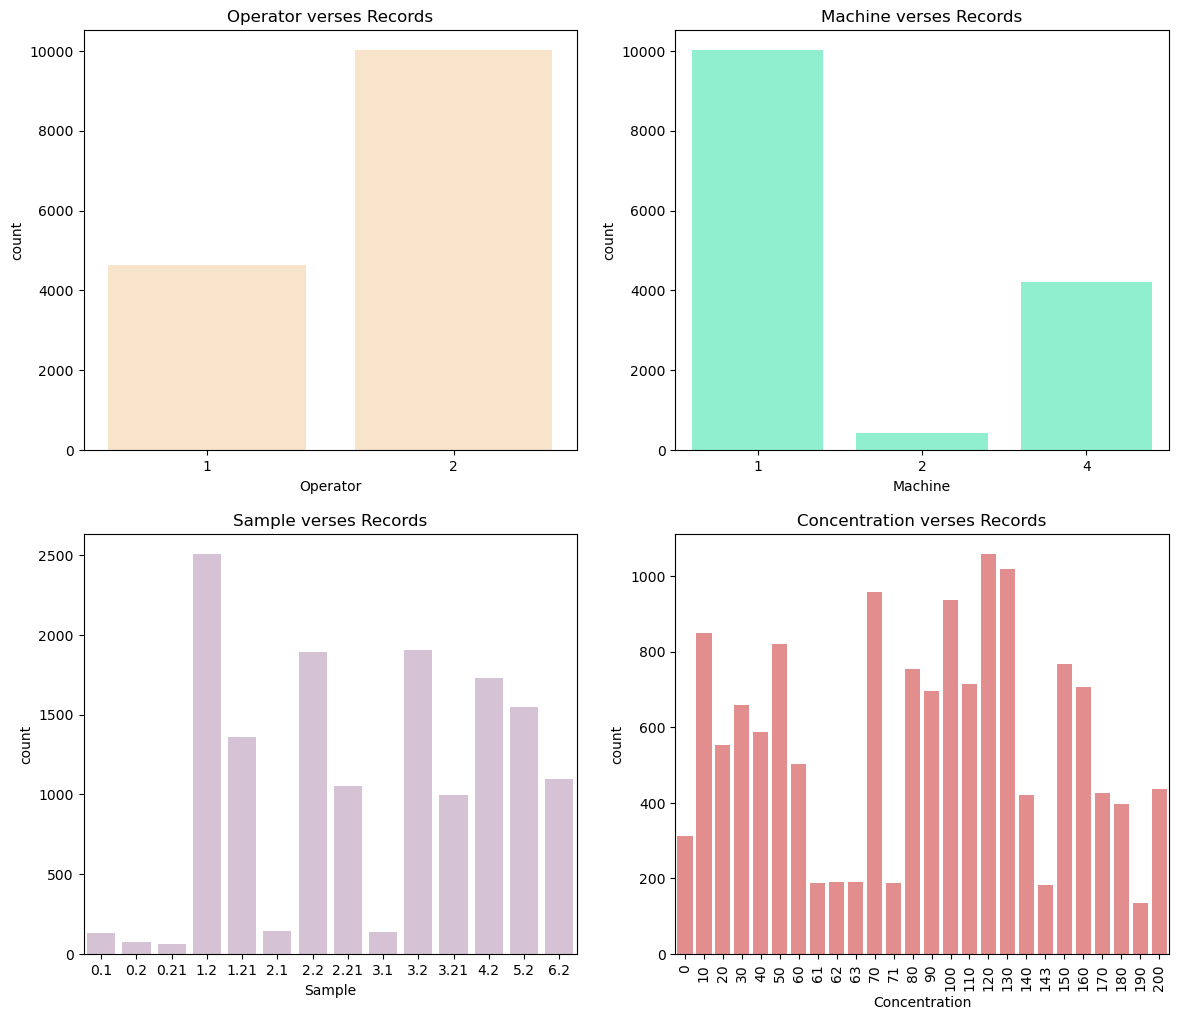

In [6]:
plt.figure(figsize=(14,12))

plt.subplot(2,2,1)
plt.title('Operator verses Records')
sns.countplot(data=data,x=data['Operator'],color='bisque')

plt.subplot(2,2,2)
plt.title('Machine verses Records')
sns.countplot(data=data, x=data['Machine'], color='aquamarine')

plt.subplot(2,2,3)
plt.title('Sample verses Records')
sns.countplot(data=data, x=data['Sample'],color='thistle')

plt.subplot(2,2,4)
plt.title('Concentration verses Records')
plot = sns.countplot(data=data,x=data['Concentration'],color='lightcoral')
plt.setp(plot.get_xticklabels(),rotation=90)

In [7]:
newdata = data.drop(columns=['Time', 'No', 'Operator', 'Machine','Solvent','Temperature'])
newdata

,Sample,Concentration,TDS,Conductivity
0,0.10,0,36.19,56.55
1,0.10,0,36.19,56.55
2,0.10,0,36.19,56.55
3,0.10,0,36.19,56.55
4,0.10,0,36.19,56.55
...,...,...,...,...
14640,3.21,200,1135.61,1774.39
14641,3.21,200,1135.61,1774.39
14642,3.21,200,1136.99,1776.55
14643,3.21,200,1136.99,1776.55


In [8]:
temp_cols = newdata.columns.tolist()
new_cols = temp_cols[1:] + temp_cols[0:1]
newdata = newdata[new_cols]
newdata.head()

,Concentration,TDS,Conductivity,Sample
0,0,36.19,56.55,0.1
1,0,36.19,56.55,0.1
2,0,36.19,56.55,0.1
3,0,36.19,56.55,0.1
4,0,36.19,56.55,0.1


In [9]:
# shuffling the rows of dataframe
newdata = newdata.sample(frac = 1)
newdata.head()

,Concentration,TDS,Conductivity,Sample
12198,130,900.60,1407.19,6.20
2950,63,400.51,625.79,1.20
12985,10,155.14,242.40,2.21
14510,150,963.18,1504.96,3.21
11060,50,357.15,558.04,1.20


In [10]:
# Encoding the target column 'Sample'
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
newdata['Sample'] = le.fit_transform(newdata['Sample'])
newdata.head()

,Concentration,TDS,Conductivity,Sample
12198,130,900.60,1407.19,13
2950,63,400.51,625.79,3
12985,10,155.14,242.40,7
14510,150,963.18,1504.96,10
11060,50,357.15,558.04,3


In [11]:
x = newdata.drop(columns=['Sample'])
y = newdata['Sample']

In [12]:
x

,Concentration,TDS,Conductivity
12198,130,900.60,1407.19
2950,63,400.51,625.79
12985,10,155.14,242.40
14510,150,963.18,1504.96
11060,50,357.15,558.04
...,...,...,...
11782,40,298.03,465.68
14332,100,620.85,970.08
856,40,394.62,616.60
1165,70,537.14,839.29


In [13]:
from sklearn.model_selection import train_test_split
from sklearn. tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.20,random_state=55)

In [15]:
model = DecisionTreeClassifier(random_state=5,max_depth=3)

In [16]:
model.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,5
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [20]:
train_score = model.score(x_train,y_train)
test_score = model.score(x_test, y_test)
print('Training Score: ',round(train_score, 2))
print('Testing Score: ',round(test_score, 2))

Training Score:  0.31
Testing Score:  0.32


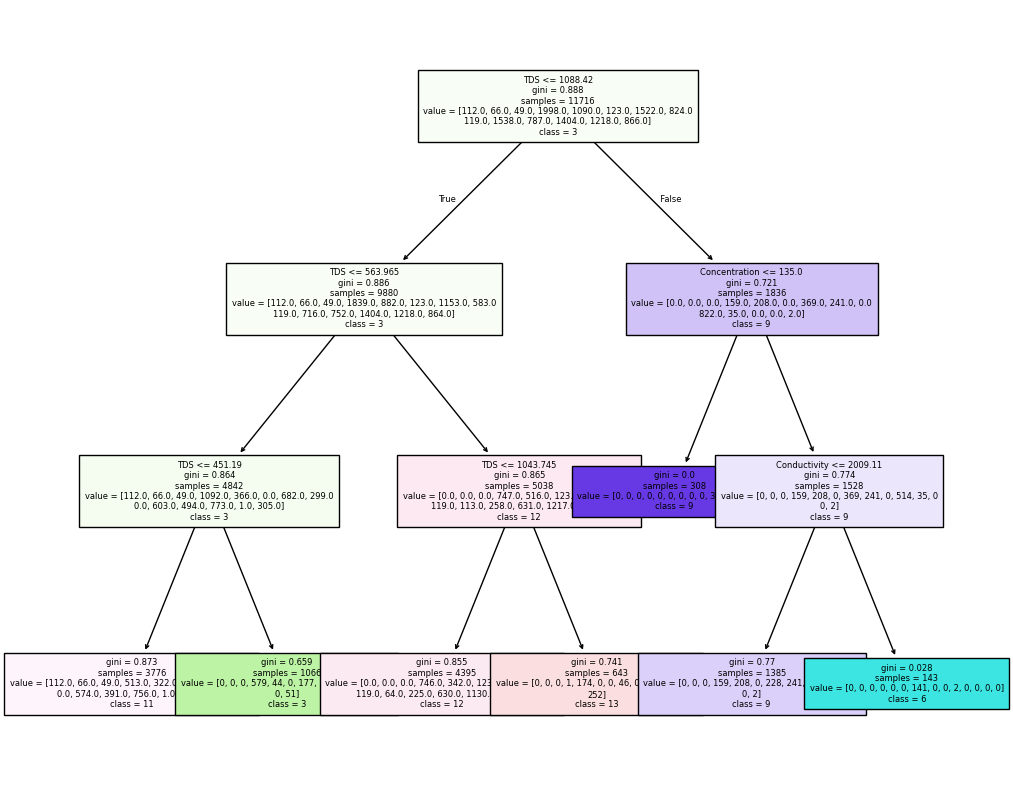

In [22]:
plt.figure(figsize=(12,10))
plot_tree(model, filled=True,feature_names=x.columns,class_names=['0','1','2','3','4','5','6','7','8', '9','10','11','12','13'],fontsize= 6)
plt.show()

In [23]:
dt = DecisionTreeClassifier()

In [24]:
my_grid = {

    'criterion':['gini','entropy'],
    'max_depth' : [4,5,6,7,8],
    'min_samples_leaf' : [1,2,3,4,5]
    }

In [25]:
from sklearn.model_selection import GridSearchCV
grid_search = GridSearchCV(dt,my_grid,cv=5,scoring='accuracy',n_jobs = -1)

In [29]:
import time
start = time.time()
grid_search.fit(x_train,y_train)
end = time.time()
print('Time taken for search: {0:.2f}'.format(end-start))

Time taken for search: 0.38


In [30]:
best_parameters = grid_search.best_params_
best_parameters

{'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 1}

In [31]:
model2 = DecisionTreeClassifier(criterion='entropy',max_depth=8,min_samples_leaf=1)

In [32]:
model2.fit(x_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [33]:
y_pred_train = model2.predict(x_train)
y_pred_test = model2.predict(x_test)

In [34]:
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)
print('Train accuracy = ',train_accuracy)
print('Test accuracy - ',test_accuracy)

Train accuracy =  0.7714236940935473
Test accuracy -  0.7801297371116422


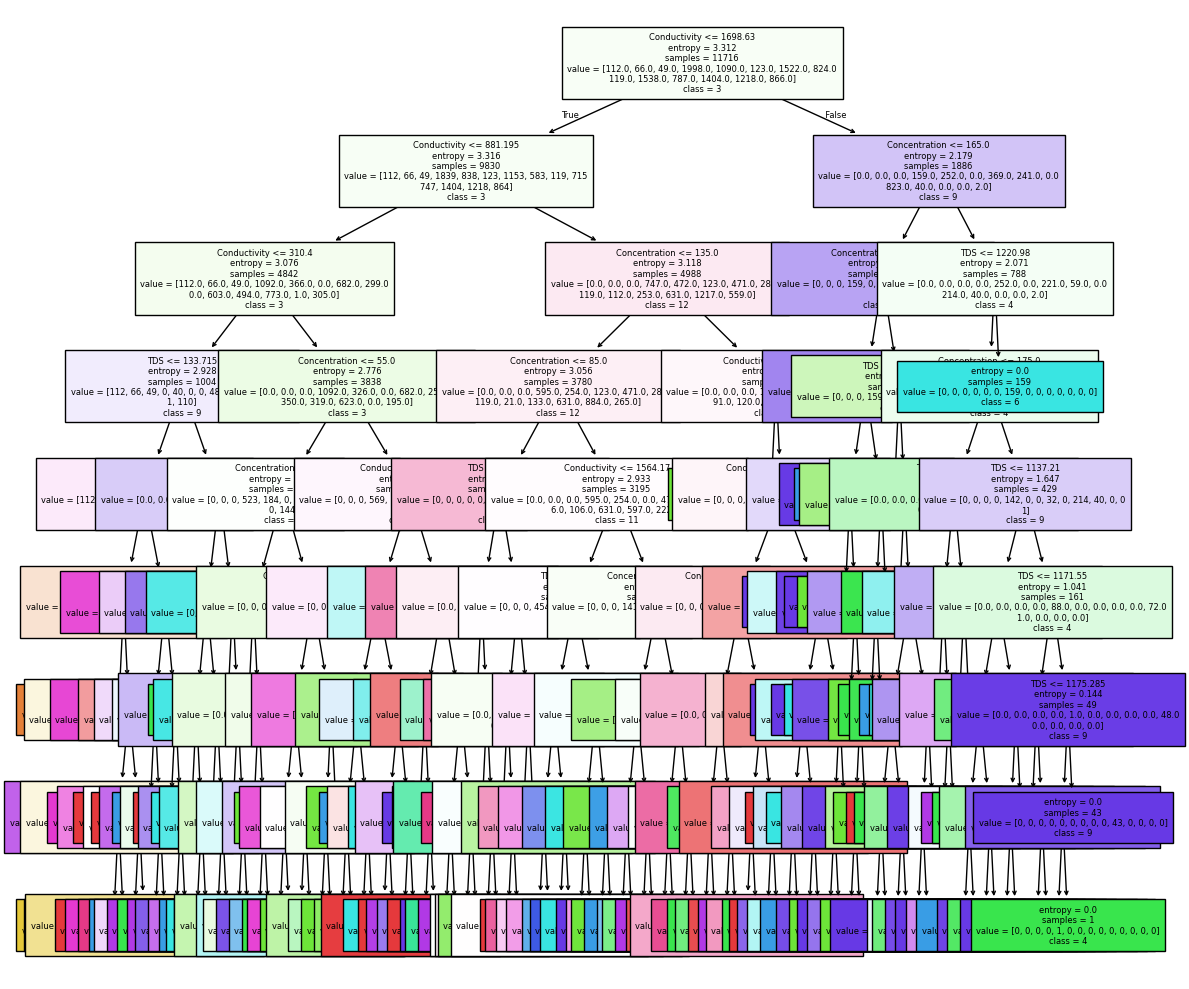

In [36]:
plt.figure(figsize=(12,10))
plot_tree(model2,filled=True, feature_names=x.columns,class_names=['0', '1','2', '3','4','5','6','7','8','9','10','11','12','13'], fontsize = 6)

plt.tight_layout()
plt. show()

In [37]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       0.67      1.00      0.80        12
           2       0.88      0.58      0.70        12
           3       0.77      0.86      0.81       508
           4       0.62      0.81      0.71       273
           5       1.00      1.00      1.00        23
           6       0.86      0.79      0.82       372
           7       0.90      0.75      0.82       226
           8       1.00      1.00      1.00        22
           9       0.94      0.81      0.87       368
          10       0.91      0.43      0.59       208
          11       0.85      0.73      0.78       328
          12       0.57      0.94      0.71       329
          13       0.95      0.62      0.75       229

    accuracy                           0.78      2929
   macro avg       0.85      0.81      0.81      2929
weighted avg       0.82      0.78      0.78      2929



In [38]:
confusion_matrix(y_test, y_pred_test)

array([[ 19,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0],
       [  0,  12,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0],
       [  0,   5,   7,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0],
       [  0,   0,   0, 436,   6,   0,   0,   0,   0,   6,   0,   0,  59,
          1],
       [  0,   0,   0,  38, 222,   0,   0,   0,   0,   1,   0,   0,  11,
          1],
       [  0,   0,   0,   0,   0,  23,   0,   0,   0,   0,   0,   0,   0,
          0],
       [  0,   0,   0,   0,  20,   0, 294,   0,   0,   1,   1,   0,  52,
          4],
       [  0,   0,   0,   6,   1,   0,  19, 169,   0,   1,   5,   0,  25,
          0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  22,   0,   0,   0,   0,
          0],
       [  0,   0,   0,   7,  18,   0,  18,  13,   0, 299,   1,   1,   9,
          2],
       [  0,   1,   1,  25,  48,   0,  10,   2,   0,  11,  90,   6,  14,
          0],
       [  0,   0,   0,   5,  40,   0,   0, 

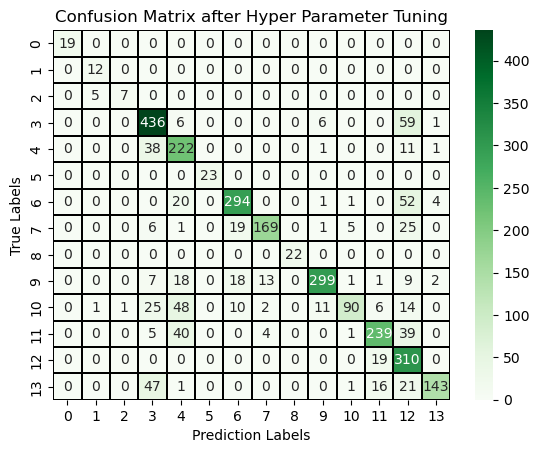

In [39]:
cm1 = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm1 , annot=True, linewidths=0.3, linecolor='black',cmap='Greens',fmt='d')
plt.xlabel('Prediction Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix after Hyper Parameter Tuning')
plt.show()

# Conclusion:
- The Training and testing score at earlier is 0.31 and 0.32 respectively.
- To improve this score we used Hper Parameter Tuning.
- The best parameters we get are criterion: entropy, max_depth: 8, min_samples_leaf: 1
- And in end the training and testing score to 0.77 and 0.78 respectively.